# Week 2, Wednesday: Naive Bayes + Pipelines


## 0. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
sns.set_theme(style='whitegrid')
np.random.seed(42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 1. Naive Bayes: the idea
Naive Bayes uses **Bayes' theorem** to compute, for a new sample, the probability of each class given its features, then picks the most probable class:

*P(class | features)  is proportional to  P(class) × P(feature 1 | class) × P(feature 2 | class) × ...*

The word **naive** refers to one assumption: it treats all features as **independent** of each other given the class, which lets it simply multiply the individual probabilities. That is rarely exactly true (in Wine, for example, several chemical features are correlated), but the model often works well anyway, and it is very fast.

**GaussianNB** assumes each feature, within each class, follows a bell curve (normal distribution). For every class it learns just a mean and a standard deviation per feature, so there is almost no tuning.

In [2]:
wine = load_wine(as_frame=True)
cancer = load_breast_cancer(as_frame=True)

# What GaussianNB actually learns: a mean and variance for every (class, feature)
nb = GaussianNB().fit(wine.data, wine.target)
learned = pd.DataFrame(nb.theta_, columns=wine.feature_names, index=wine.target_names)
print('Class priors P(class):', dict(zip(wine.target_names, nb.class_prior_.round(3))))
display(learned[['alcohol', 'flavanoids', 'color_intensity']].round(2))

Class priors P(class): {np.str_('class_0'): np.float64(0.331), np.str_('class_1'): np.float64(0.399), np.str_('class_2'): np.float64(0.27)}


,alcohol,flavanoids,color_intensity
class_0,13.74,2.98,5.53
class_1,12.28,2.08,3.09
class_2,13.15,0.78,7.40


In [3]:
variances = pd.DataFrame(
    nb.var_,
    columns=wine.feature_names,
    index=wine.target_names
)

display(
    variances[['alcohol', 'flavanoids', 'color_intensity']].round(2)
)

,alcohol,flavanoids,color_intensity
class_0,0.21,0.16,1.51
class_1,0.29,0.49,0.84
class_2,0.28,0.08,5.23


## 2. Compare GaussianNB with Tree and kNN on Wine and Breast Cancer

dataset,Breast Cancer,Wine
model,,
Decision Tree (depth 3),0.924,0.876
GaussianNB,0.939,0.972
kNN k=5 (scaled),0.963,0.972


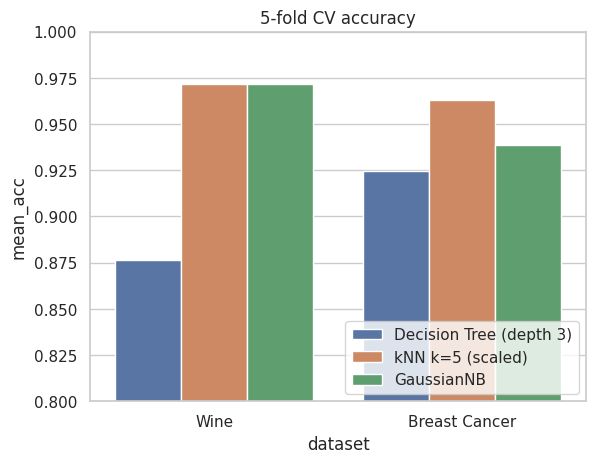

In [4]:
models = {
    'Decision Tree (depth 3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'kNN k=5 (scaled)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'GaussianNB': GaussianNB(),
}
rows = []
for dname, d in [('Wine', wine), ('Breast Cancer', cancer)]:
    for mname, m in models.items():
        s = cross_val_score(m, d.data, d.target, cv=cv)
        rows.append((dname, mname, s.mean(), s.std()))
res = pd.DataFrame(rows, columns=['dataset', 'model', 'mean_acc', 'std'])
display(res.pivot(index='model', columns='dataset', values='mean_acc').round(3))
sns.barplot(data=res, x='dataset', y='mean_acc', hue='model'); plt.ylim(0.8, 1.0); plt.title('5-fold CV accuracy'); plt.legend(loc='lower right'); plt.show()

In [5]:
# Does scaling matter for Naive Bayes? (It shouldn't: each feature is modelled on its own.)
for name, m in [('GaussianNB raw', GaussianNB()), ('GaussianNB scaled', make_pipeline(StandardScaler(), GaussianNB()))]:
    print(name, round(cross_val_score(m, wine.data, wine.target, cv=cv).mean(), 3))

GaussianNB raw 0.972
GaussianNB scaled 0.977


## 3. Pipelines: why we need them
On Monday we imputed, encoded and scaled **step by step**, fitting each step on the training data by hand. That is easy to get wrong: one slip (fitting a scaler on all the data) leaks test information.

A **Pipeline** chains the steps and the model into **one object**. Calling `.fit(X_train, y_train)` fits every step on the training data only, and `.predict(X_new)` pushes raw data through all the steps automatically. Inside `cross_val_score`, it refits the preprocessing on each training fold, so there is **no leakage**.

A **ColumnTransformer** applies different preprocessing to different columns (numbers vs categories).

In [6]:
df = sns.load_dataset('titanic')
num_cols = ['age', 'fare', 'sibsp', 'parch', 'pclass']
cat_cols = ['sex', 'embarked']
X = df[num_cols + cat_cols]
y = df['survived']
print(X.isnull().sum()[X.isnull().sum() > 0])

age         177
embarked      2
dtype: int64


In [7]:
numeric_pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('scale', StandardScaler())])
categorical_pipe = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                             ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocess = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', categorical_pipe, cat_cols),
])
preprocess

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['age', 'fare', 'sibsp', 'parch', 'pclass']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'embarked'])])

Now one object that goes from **raw** Titanic data to a prediction. Notice the model is the *last step*; changing the classifier is a one-line change.

In [8]:
clf = Pipeline([('prep', preprocess),
                ('model', DecisionTreeClassifier(max_depth=4, random_state=42))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
clf.fit(X_train, y_train)
print('Test accuracy:', round(clf.score(X_test, y_test), 3))
print('Predictions for 5 raw (unprocessed) passengers:', clf.predict(X_test.head(5)), ' actual:', y_test.head(5).values)

Test accuracy: 0.788
Predictions for 5 raw (unprocessed) passengers: [0 0 0 0 1]  actual: [0 0 1 0 1]


## 4. Swap the classifier: tree, kNN, Naive Bayes in the same pipeline

In [9]:
classifiers = {
    'Decision Tree (depth 4)': DecisionTreeClassifier(max_depth=4, random_state=42),
    'kNN k=5': KNeighborsClassifier(n_neighbors=5),
    'GaussianNB': GaussianNB(),
}
# GaussianNB needs a dense array, and the OneHotEncoder may return a sparse one, so we ask for dense output
preprocess_dense = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
])

titanic_scores = {}
for name, model in classifiers.items():
    pipe = Pipeline([('prep', preprocess_dense), ('model', model)])      # <- only the model changes
    s = cross_val_score(pipe, X, y, cv=cv)
    titanic_scores[name] = s
    print(f'{name:26s} mean={s.mean():.3f}  std={s.std():.3f}  folds={np.round(s, 3)}')

Decision Tree (depth 4)    mean=0.818  std=0.016  folds=[0.827 0.826 0.792 0.809 0.837]
kNN k=5                    mean=0.813  std=0.018  folds=[0.81  0.803 0.787 0.837 0.826]
GaussianNB                 mean=0.787  std=0.017  folds=[0.765 0.775 0.792 0.787 0.815]


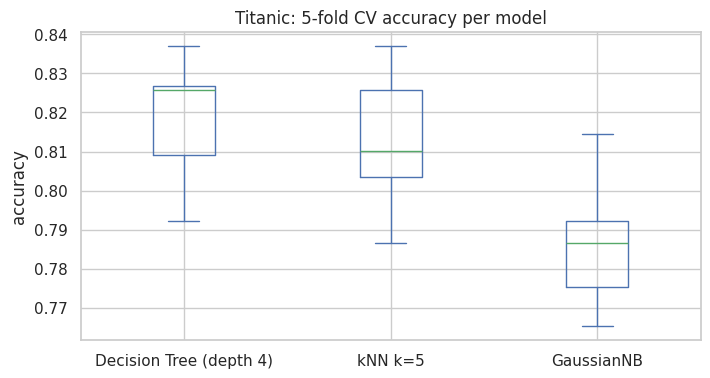

Baseline (always predict not survived): 0.616


In [10]:
pd.DataFrame({k: v for k, v in titanic_scores.items()}).plot.box(figsize=(8, 4), title='Titanic: 5-fold CV accuracy per model')
plt.ylabel('accuracy'); plt.show()
# Majority-class baseline for reference
print('Baseline (always predict not survived):', round(1 - y.mean(), 3))

## 5. Why a Pipeline prevents leakage:
Below, we compare a **leaky** workflow (scale on all the data, then cross-validate) with the **correct** pipeline. On this dataset the difference will be tiny, but the leaky version gives the model information about the held-out fold. On small datasets or with more aggressive preprocessing the gap can be larger. The point is to know which one is correct.

In [11]:
# LEAKY: the scaler sees ALL rows (including the rows that will be used for testing in each fold)
X_leaky = StandardScaler().fit_transform(wine.data)
leaky = cross_val_score(KNeighborsClassifier(5), X_leaky, wine.target, cv=cv).mean()

# CORRECT: the scaler is refit on the training part of each fold
correct = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), wine.data, wine.target, cv=cv).mean()
print(f'Leaky CV accuracy   : {leaky:.4f}')
print(f'Pipeline CV accuracy: {correct:.4f}')

Leaky CV accuracy   : 0.9717
Pipeline CV accuracy: 0.9717
